# Logistic Regression - Loan Approval Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, roc_curve, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

### Question 1: Data Loading & Understanding

-->  

**a) Load the dataset into Python.**

In [2]:
# in colab upload the file first or give the drive path
df = pd.read_excel('loan_approval.xlsx')

**b) Display the first 5 rows.**

In [3]:
df.head()

,name,city,income,credit_score,loan_amount,years_employed,points,loan_approved
0,Allison Hill,East Jill,113810,389,39698,27,50,False
1,Brandon Hall,New Jamesside,44592,729,15446,28,55,False
2,Rhonda Smith,Lake Roberto,33278,584,11189,13,45,False
3,Gabrielle Davis,West Melanieview,127196,344,48823,29,50,False
4,Valerie Gray,Mariastad,66048,496,47174,4,25,False


**c) Check the shape of the dataset.**

In [4]:
print("Shape of dataset :", df.shape)
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Shape of dataset : (2000, 8)
Rows : 2000
Columns : 8


**d) Display the data types of each column.**

In [5]:
df.dtypes

name                str
city                str
income            int64
credit_score      int64
loan_amount       int64
years_employed    int64
points            int64
loan_approved      bool
dtype: object

In [6]:
df.describe()

,income,credit_score,loan_amount,years_employed,points
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,90585.977000,579.807000,25308.503000,20.482000,56.680000
std,34487.874907,243.536494,14207.320147,11.873928,18.638033
min,30053.000000,11.000000,1022.000000,-5.000000,10.000000
25%,61296.250000,433.000000,12748.750000,10.000000,45.000000
50%,90387.500000,576.000000,25661.500000,21.000000,55.000000
75%,120099.750000,716.000000,37380.500000,31.000000,70.000000
max,149964.000000,6548.000000,49999.000000,70.000000,100.000000


Answer:
The dataset is loaded using **pandas** with the `read_excel()` function because the data is given in an Excel file. After loading, the first 5 rows were checked with `head()` to get an idea of what each column looks like.

The dataset has **2000 rows and 8 columns**. Each row is one loan applicant and the columns are name, city, income, credit_score, loan_amount, years_employed, points and loan_approved.

Looking at the data types, **name** and **city** are text (object/string) columns, **income, credit_score, loan_amount, years_employed and points** are integer columns, and the target column **loan_approved** is stored as boolean (True / False).

From `describe()` we can also see a few strange values. The credit_score goes up to **6548**, which is not a real credit score, and years_employed has a minimum of **-5**, which is not possible. These things will be handled in the cleaning and outlier steps.

So in short, the dataset is small and mostly numerical, and the target column is already in a yes/no form which suits Logistic Regression.

---
---

### Question 2: Data Cleaning

-->  

**a) Check for missing values in the dataset.**

In [7]:
df.isnull().sum()

name              0
city              0
income            0
credit_score      0
loan_amount       0
years_employed    0
points            0
loan_approved     0
dtype: int64

In [8]:
print("Duplicate rows :", df.duplicated().sum())

Duplicate rows : 0


**b) Handle missing values appropriately.**

In [9]:
# no null values, but years_employed has a negative value which is not possible
print("Negative years_employed :", (df['years_employed'] < 0).sum())

# treating negative experience as missing and filling it with median
df.loc[df['years_employed'] < 0, 'years_employed'] = np.nan
df['years_employed'] = df['years_employed'].fillna(df['years_employed'].median())

print("After fixing :", (df['years_employed'] < 0).sum())
df.isnull().sum()

Negative years_employed : 1
After fixing : 0


name              0
city              0
income            0
credit_score      0
loan_amount       0
years_employed    0
points            0
loan_approved     0
dtype: int64

**c) Identify categorical columns present in the dataset.**

In [10]:
cat_cols = df.select_dtypes(include=['object', 'string', 'bool']).columns.tolist()
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical columns :", cat_cols)
print("Numerical columns :", num_cols)

Categorical columns : ['name', 'city', 'loan_approved']
Numerical columns : ['income', 'credit_score', 'loan_amount', 'years_employed', 'points']


In [11]:
for col in ['name', 'city']:
    print(col, "unique values :", df[col].nunique())

name unique values : 2000
city unique values : 1882


Answer:
Data cleaning is the step where we check the data for problems like missing values, wrong entries and duplicates before using it for analysis or modelling.

First, `isnull().sum()` was used to check missing values. The result shows **0 missing values in every column**, and there are also **no duplicate rows** in the dataset.

But even though nothing was null, one record had **years_employed = -5**. Employment years can never be negative, so this is basically a wrong or missing entry. I converted it to NaN and filled it with the **median** of the column. Median is used instead of mean because it is not affected much by extreme values.

Next, the **categorical columns** were identified. These are **name, city and loan_approved**. Here name is unique for all 2000 rows and city has 1882 unique values, so both of them work like ID columns and will not help the model. loan_approved is the target column.

Finally, the numerical columns are income, credit_score, loan_amount, years_employed and points, and these will be used further in EDA and model building.

---
---

### Question 3: Exploratory Data Analysis (EDA)

-->  

**a) Plot the distribution of the target variable.**

loan_approved
False    1121
True      879
Name: count, dtype: int64

loan_approved
False    56.05
True     43.95
Name: proportion, dtype: float64


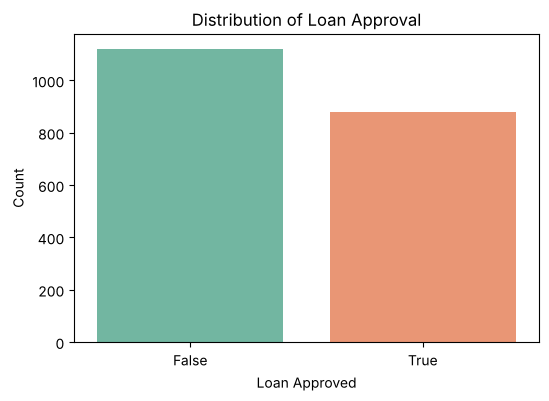

In [12]:
print(df['loan_approved'].value_counts())
print()
print(df['loan_approved'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6,4))
sns.countplot(x='loan_approved', data=df, palette='Set2')
plt.title('Distribution of Loan Approval')
plt.xlabel('Loan Approved')
plt.ylabel('Count')
plt.show()

**b) Analyze the relationship between one numerical feature and the target variable.**

                     mean  median
loan_approved                    
False          482.107939   463.0
True           704.403868   729.0


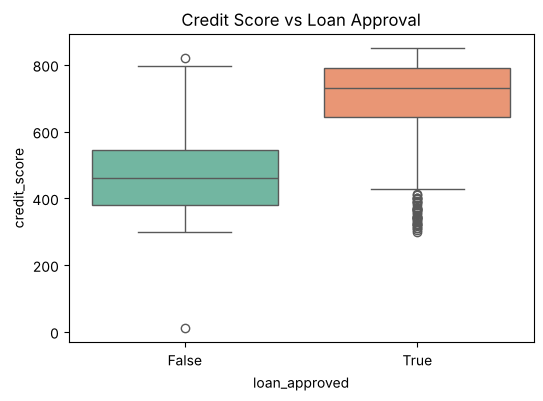

In [13]:
print(df.groupby('loan_approved')['credit_score'].agg(['mean', 'median']))

plt.figure(figsize=(6,4))
sns.boxplot(x='loan_approved', y='credit_score', data=df[df['credit_score'] < 1000], palette='Set2')
plt.title('Credit Score vs Loan Approval')
plt.show()

                     income   loan_amount
loan_approved                            
False          83317.456735  27293.981267
True           99855.614334  22776.397042


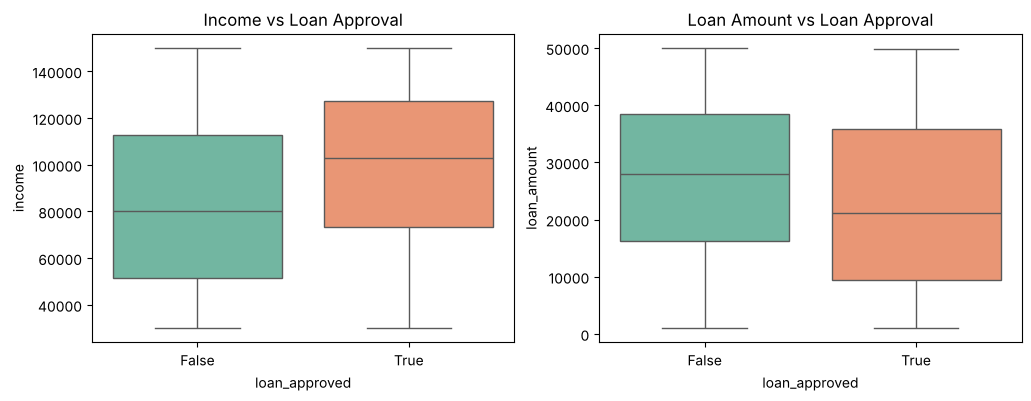

In [14]:
print(df.groupby('loan_approved')[['income', 'loan_amount']].mean())

fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x='loan_approved', y='income', data=df, palette='Set2', ax=ax[0])
ax[0].set_title('Income vs Loan Approval')
sns.boxplot(x='loan_approved', y='loan_amount', data=df, palette='Set2', ax=ax[1])
ax[1].set_title('Loan Amount vs Loan Approval')
plt.show()

**c) Analyze the relationship between Years of Employment and the target variable.**

                    mean  median
loan_approved                   
False          19.448707    20.0
True           21.829352    22.0


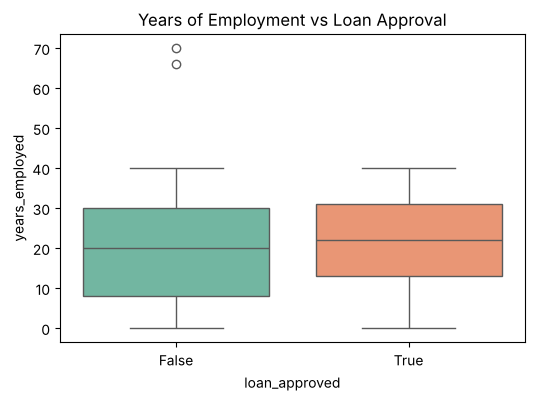

In [15]:
print(df.groupby('loan_approved')['years_employed'].agg(['mean', 'median']))

plt.figure(figsize=(6,4))
sns.boxplot(x='loan_approved', y='years_employed', data=df, palette='Set2')
plt.title('Years of Employment vs Loan Approval')
plt.show()

emp_group
0-5      25.68
6-10     40.30
11-20    48.13
21-30    47.97
31-40    47.50
40+       0.00
Name: loan_approved, dtype: float64


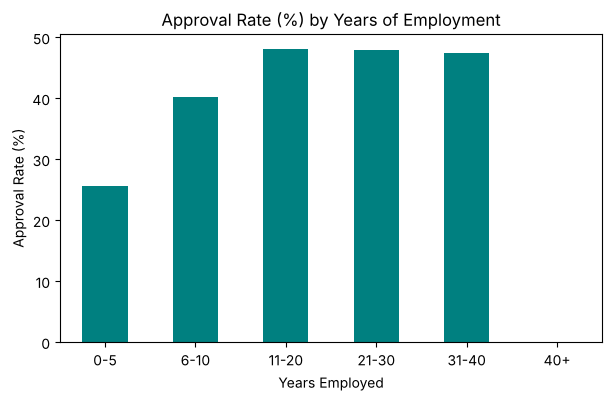

In [16]:
df['emp_group'] = pd.cut(df['years_employed'], bins=[-1, 5, 10, 20, 30, 40, 70],
                         labels=['0-5', '6-10', '11-20', '21-30', '31-40', '40+'])

emp_rate = df.groupby('emp_group')['loan_approved'].mean() * 100
print(emp_rate.round(2))

emp_rate.plot(kind='bar', color='teal', figsize=(7,4))
plt.title('Approval Rate (%) by Years of Employment')
plt.ylabel('Approval Rate (%)')
plt.xlabel('Years Employed')
plt.xticks(rotation=0)
plt.show()

df.drop(columns='emp_group', inplace=True)

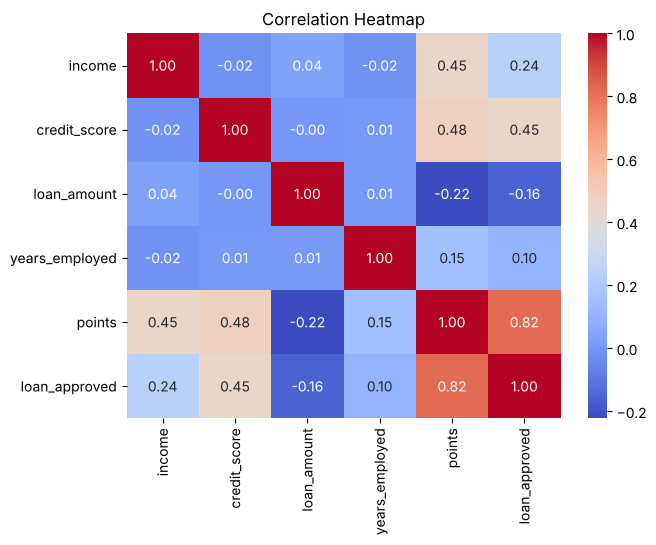

In [17]:
plt.figure(figsize=(7,5))
sns.heatmap(df[num_cols + ['loan_approved']].astype(float).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Answer:
EDA helps us understand the data better by looking at patterns, distributions and how each feature is related to the target.

First, the target variable **loan_approved** was plotted. Out of 2000 applicants, **1121 (about 56%) were not approved** and **879 (about 44%) were approved**. So the classes are slightly imbalanced but not too much, and the model can still learn both classes properly.

For the numerical feature, I mainly looked at **credit_score**. Approved applicants have an average credit score of around **704**, while rejected ones are around **482**. The boxplot also clearly shows that approved people have much higher credit scores. Income shows a similar trend, approved applicants earn more on average (about 99,856 vs 83,317), while the **loan amount is lower** for approved applicants. So people asking for a smaller loan with a better score and income have a better chance.

For **Years of Employment**, the difference is smaller. Approved applicants have about **21.8 years** on average and rejected ones about **19.4 years**. When grouped, people with **0-5 years** of experience have only about **26% approval**, and it increases to around **48%** for people with more than 10 years. After that it stays almost flat. The 40+ group shows 0% but it has only 2 people, so it is not really meaningful. So experience helps a little, but it is not as strong as credit score.

Finally, the correlation heatmap shows that **points** has an extremely high correlation with loan_approved. This is checked again in Question 5.

So overall, credit score, income and loan amount look like the most useful features, and years of employment has a small positive effect.

---
---

### Question 4: Outlier Detection and Treatment

-->  

**a) Detect outliers in numerical columns using the IQR method.**

In [18]:
def iqr_limits(col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

for col in num_cols:
    low, high = iqr_limits(col)
    count = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:15} lower = {low:10.2f}   upper = {high:10.2f}   outliers = {count}")

income          lower =  -26909.00   upper =  208305.00   outliers = 0
credit_score    lower =       8.50   upper =    1140.50   outliers = 3
loan_amount     lower =  -24198.88   upper =   74328.12   outliers = 0
years_employed  lower =     -21.50   upper =      62.50   outliers = 2
points          lower =       7.50   upper =     107.50   outliers = 0


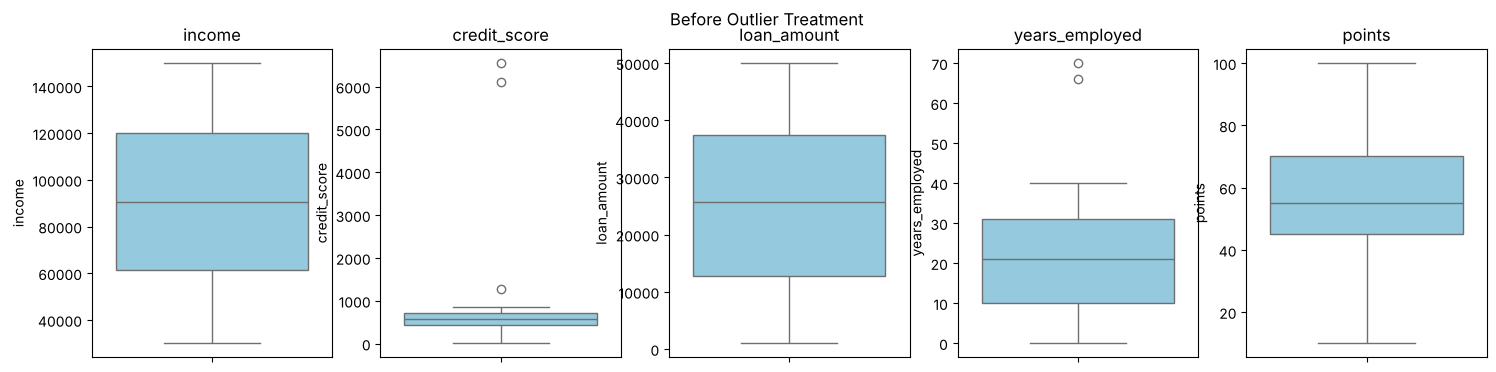

In [19]:
fig, ax = plt.subplots(1, len(num_cols), figsize=(18,4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=ax[i], color='skyblue')
    ax[i].set_title(col)
plt.suptitle('Before Outlier Treatment')
plt.show()

**b) Treat outliers using capping techniques**

In [20]:
for col in num_cols:
    low, high = iqr_limits(col)
    df[col] = np.where(df[col] < low, low, df[col])
    df[col] = np.where(df[col] > high, high, df[col])

for col in num_cols:
    low, high = iqr_limits(col)
    print(col, "outliers after capping :", ((df[col] < low) | (df[col] > high)).sum())

income outliers after capping : 0
credit_score outliers after capping : 0
loan_amount outliers after capping : 0
years_employed outliers after capping : 0
points outliers after capping : 0


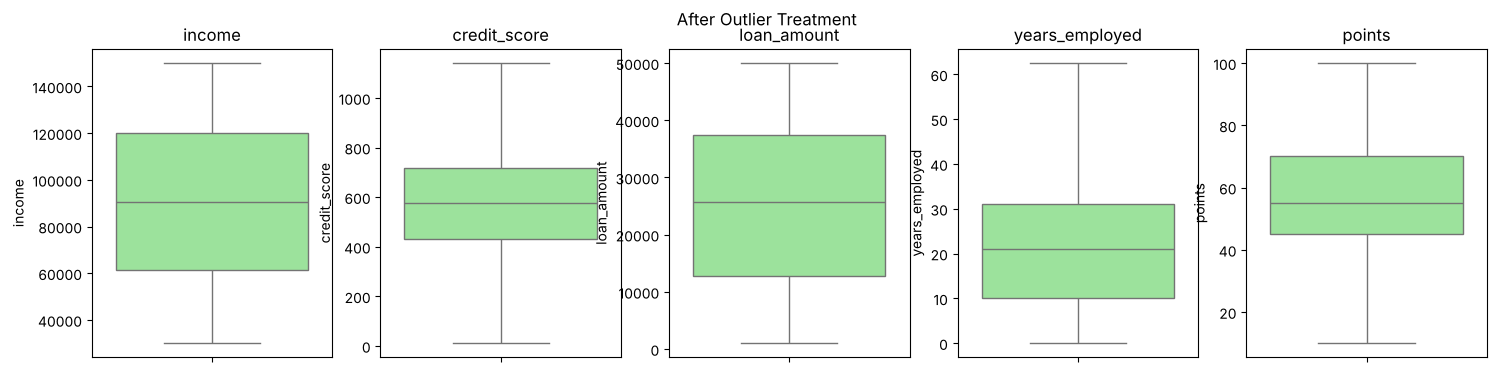

In [21]:
fig, ax = plt.subplots(1, len(num_cols), figsize=(18,4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=ax[i], color='lightgreen')
    ax[i].set_title(col)
plt.suptitle('After Outlier Treatment')
plt.show()

Answer:
Outliers are values that are very far from the rest of the data. In Logistic Regression they can pull the coefficients in the wrong direction, so it is better to handle them before training.

The **IQR method** was used to find them. First Q1 (25th percentile) and Q3 (75th percentile) are calculated, and **IQR = Q3 - Q1**. Any value below **Q1 - 1.5 x IQR** or above **Q3 + 1.5 x IQR** is treated as an outlier.

Using this, outliers were found only in two columns. **credit_score had 3 outliers** (values like 6548 and 6110 which are clearly wrong entries) and **years_employed had 2 outliers** (66 and 70 years). Income, loan_amount and points did not have any outliers.

To treat them, **capping** was used. This means values above the upper limit are replaced by the upper limit and values below the lower limit are replaced by the lower limit. For example, a credit score of 6548 now becomes 1140.5. The good thing about capping is that we do not lose any rows, we only bring the extreme values closer to normal.

After capping, all columns show **0 outliers** and the boxplots look much cleaner.

---
---

### Question 5: Convert target variables into numerical format suitable for model building and drop unnecessary columns.

-->  

In [22]:
df['loan_approved'] = df['loan_approved'].astype(int)
df['loan_approved'].value_counts()

loan_approved
0    1121
1     879
Name: count, dtype: int64

In [23]:
# checking points column against target
pd.crosstab(df['points'], df['loan_approved'])

loan_approved,0,1
points,,
10.0,4,0
15.0,3,0
20.0,18,0
25.0,95,0
30.0,59,0
35.0,127,0
40.0,164,0
45.0,170,0
50.0,271,0


In [24]:
df = df.drop(columns=['name', 'city', 'points'])
df.head()

,income,credit_score,loan_amount,years_employed,loan_approved
0,113810.0,389.0,39698.0,27.0,0
1,44592.0,729.0,15446.0,28.0,0
2,33278.0,584.0,11189.0,13.0,0
3,127196.0,344.0,48823.0,29.0,0
4,66048.0,496.0,47174.0,4.0,0


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   income          2000 non-null   float64
 1   credit_score    2000 non-null   float64
 2   loan_amount     2000 non-null   float64
 3   years_employed  2000 non-null   float64
 4   loan_approved   2000 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 78.3 KB


Answer:
Machine learning models work only with numbers, so the target column has to be in numeric form. The **loan_approved** column was True / False, so it was converted using `astype(int)`. Now **1 means approved** and **0 means not approved**.

Next, unnecessary columns were dropped. **name** is different for every person and **city** has 1882 unique values out of 2000 rows, so both of them do not carry any useful pattern and would only add noise.

I also dropped the **points** column. When I checked it with a crosstab, every applicant with **60 or more points was approved** and every applicant **below 60 was rejected**, without a single exception. This means points is basically the final decision score itself and not a customer detail. If we keep it, the model gives 100% accuracy just by looking at this one column, which is called **data leakage**. In real life we would not have this score before the decision, so it is removed.

Finally, the dataset is left with **income, credit_score, loan_amount, years_employed** as features and **loan_approved** as the target, all in numeric format and ready for model building.

---
---

### Question 6: Feature Selection and Data Splitting

-->  

**a) Separate independent variables (X) and dependent variable (y).**

In [26]:
X = df.drop(columns='loan_approved')
y = df['loan_approved']

print("X shape :", X.shape)
print("y shape :", y.shape)
X.head()

X shape : (2000, 4)
y shape : (2000,)


,income,credit_score,loan_amount,years_employed
0,113810.0,389.0,39698.0,27.0
1,44592.0,729.0,15446.0,28.0
2,33278.0,584.0,11189.0,13.0
3,127196.0,344.0,48823.0,29.0
4,66048.0,496.0,47174.0,4.0


**b) Split the dataset into training and testing sets.**

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print()
print("Train approval ratio :", round(y_train.mean(), 3))
print("Test approval ratio  :", round(y_test.mean(), 3))

X_train : (1600, 4)
X_test  : (400, 4)

Train approval ratio : 0.439
Test approval ratio  : 0.44


Answer:
Before training, the data is divided into **independent variables (X)** and the **dependent variable (y)**. X contains the inputs that the model learns from, which are **income, credit_score, loan_amount and years_employed**. y is the output we want to predict, which is **loan_approved**.

After that, the data was split into training and testing sets using `train_test_split()`. I used **80% for training (1600 rows)** and **20% for testing (400 rows)**. The model learns only from the training data, and the testing data is kept aside to check how well it works on new data it has never seen.

I also used **stratify=y** so that both train and test have the same proportion of approved and rejected loans (around 44% approved in both). Without this, one set might get more of one class just by chance.

**random_state=42** is set so that the split stays the same every time the notebook is run, which makes the results repeatable.

---
---

### Question 7: Apply feature scaling to the dataset using StandardScaler.

-->  

In [28]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).describe().round(2)

,income,credit_score,loan_amount,years_employed
count,1600.00,1600.00,1600.00,1600.00
mean,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.77,-3.47,-1.70,-1.74
25%,-0.86,-0.87,-0.89,-0.90
50%,0.00,0.02,0.02,0.03
75%,0.86,0.86,0.85,0.88
max,1.72,3.48,1.75,3.54


Answer:
Feature scaling is used to bring all the features to a similar range. In this dataset income is in thousands (around 90,000), loan_amount is around 25,000, credit_score is in hundreds and years_employed is only up to around 60. Without scaling, the columns with big numbers can dominate the model.

**StandardScaler** converts each column so that it has a **mean of 0 and standard deviation of 1**. The formula is **z = (x - mean) / standard deviation**. After scaling, the describe table shows mean = 0 and std = 1 for all four features.

One important thing here is that the scaler is **fit only on the training data** using `fit_transform()`, and then the same scaler is applied to the test data using `transform()`. If we fit on the full data, some information from the test set would leak into training.

Scaling also helps Logistic Regression converge faster, and it makes the coefficients comparable with each other, so we can see which feature has more effect on the result.

---
---

### Question 8: Logistic Regression Model Building

-->  

**a) Train a Logistic Regression model.**

In [29]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

print("Intercept :", model.intercept_[0])
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0], 'Odds Ratio': np.exp(model.coef_[0])})
coef_df

Intercept : -0.7321392472040521


,Feature,Coefficient,Odds Ratio
0,income,1.609029,4.997956
1,credit_score,3.589297,36.208621
2,loan_amount,-1.041676,0.352863
3,years_employed,0.535341,1.708031


In [30]:
# regression equation
b0 = model.intercept_[0]
eq = f"log(p / (1 - p)) = {b0:.4f}"
for f, c in zip(X.columns, model.coef_[0]):
    eq += f" {'+' if c >= 0 else '-'} {abs(c):.4f} * {f}"
print(eq)

log(p / (1 - p)) = -0.7321 + 1.6090 * income + 3.5893 * credit_score - 1.0417 * loan_amount + 0.5353 * years_employed


**b) Predict the output for test data.**

In [31]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

result = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred, 'Probability': y_prob.round(3)})
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
result.head(10)

Accuracy : 0.94


,Actual,Predicted,Probability
0,1,0,0.446
1,0,0,0.013
2,1,1,0.943
3,1,1,0.943
4,0,0,0.019
5,1,1,0.999
6,0,0,0.004
7,1,1,0.987
8,0,0,0.088
9,0,0,0.016


Answer:
Logistic Regression is a classification algorithm that predicts the **probability** of something happening. It first calculates a linear equation and then passes it through the **sigmoid function**, which converts the value between 0 and 1. If the probability is 0.5 or more, the loan is predicted as approved (1), otherwise not approved (0).

The model was trained on the scaled training data using `fit()`. The final **regression equation** is:

**log(p / (1 - p)) = -0.7321 + 1.6090(income) + 3.5893(credit_score) - 1.0417(loan_amount) + 0.5353(years_employed)**

where p is the probability of loan approval and all features are in scaled form.

**Interpretation of coefficients:**
**credit_score (3.59)** has the biggest positive effect. If credit score increases by one standard deviation, the odds of approval go up by around **36 times** (e^3.59). So credit score is the most important factor.

**income (1.61)** is also positive. One standard deviation more income increases the odds of approval by around **5 times**.

**loan_amount (-1.04)** is negative, which means asking for a bigger loan reduces the chances. One standard deviation increase in loan amount cuts the odds to about **0.35 times**.

**years_employed (0.54)** is positive but small, so more experience helps a little (around **1.7 times** odds). This matches what we saw in EDA.

The **intercept (-0.73)** is the log odds when all features are at their average value, which means an average applicant is slightly more likely to be rejected.

After training, predictions were made on the test data using `predict()` and the probabilities using `predict_proba()`. The model gives an **accuracy of 94%** on the test set.

---
---

### Question 9: Model Evaluation – Confusion Matrix

-->  

**a) Generate the confusion matrix.**

[[216   8]
 [ 16 160]]


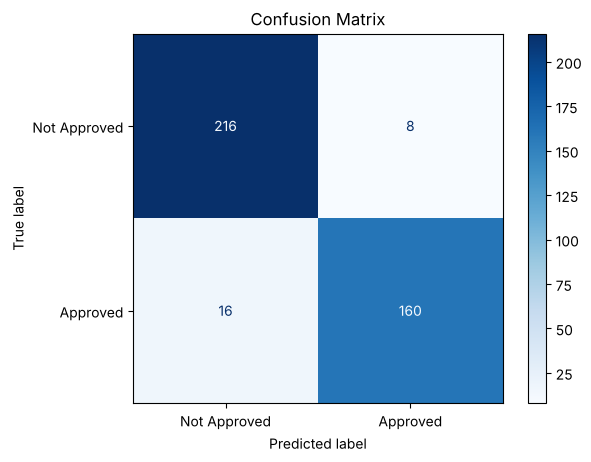

In [32]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['Not Approved', 'Approved']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

In [33]:
tn, fp, fn, tp = cm.ravel()
print("True Negative  :", tn)
print("False Positive :", fp)
print("False Negative :", fn)
print("True Positive  :", tp)
print()
print(classification_report(y_test, y_pred, target_names=['Not Approved', 'Approved']))

True Negative  : 216
False Positive : 8
False Negative : 16
True Positive  : 160



              precision    recall  f1-score   support

Not Approved       0.93      0.96      0.95       224
    Approved       0.95      0.91      0.93       176

    accuracy                           0.94       400
   macro avg       0.94      0.94      0.94       400
weighted avg       0.94      0.94      0.94       400



**b) Interpret the results.**

Answer:
A confusion matrix shows how many predictions were correct and how many were wrong for each class. It has four parts: True Positive, True Negative, False Positive and False Negative.

From the test set of 400 applicants, the results are:
**True Negative = 216** : loans that were rejected and the model also predicted rejected.
**True Positive = 160** : loans that were approved and the model also predicted approved.
**False Positive = 8** : loans that were actually rejected but the model said approved.
**False Negative = 16** : loans that were actually approved but the model said rejected.

So the model got **376 out of 400 correct**, which is **94% accuracy**. The **precision** for approved loans is about **0.95**, which means when the model says approve, it is right 95% of the time. The **recall** for approved loans is about **0.91**, so it catches 91% of the people who actually deserve approval.

For a bank, **False Positives are more risky** because giving a loan to the wrong person can lead to loss. Here there are only 8 such cases, which is good. The 16 False Negatives mean some good customers are being rejected, which is a loss of business but less dangerous.

Overall the confusion matrix shows the model is quite reliable and makes few mistakes on both sides.

---
---

### Question 10: Model Evaluation – ROC Curve & AUC

-->  

**a) Plot the ROC curve.**

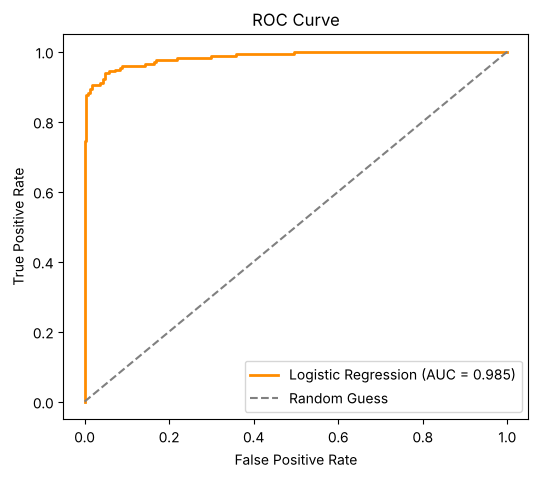

In [34]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

**b) Calculate the AUC score.**

In [35]:
print("AUC Score :", round(auc, 4))

AUC Score : 0.9852


Answer:
The **ROC curve** (Receiver Operating Characteristic) shows how the model performs at different threshold values. It plots the **True Positive Rate** on the y-axis against the **False Positive Rate** on the x-axis. The dotted diagonal line is what a random guess would look like.

In our plot, the orange curve goes up very close to the **top-left corner**. This means the model is able to get a high true positive rate while keeping false positives low, which is what we want.

**AUC** (Area Under the Curve) gives this in one number between 0 and 1. An AUC of 0.5 means the model is no better than guessing, and 1 means perfect. Our model got an **AUC score of about 0.985**.

This means if we pick one approved applicant and one rejected applicant randomly, there is about a **98.5% chance** the model gives a higher approval probability to the approved one.

So the model separates approved and rejected loans very well, and Logistic Regression works well for this problem, with credit score, income and loan amount being the main factors behind the decision.